# Airline credit: losses, limits and recovery
Research cutoff: 25 October 2026. Read the [investor narrative](../docs/credit-story.md) and [benchmark research](../docs/airline-credit-benchmarks.md). This workbook reproduces a loss history and **hypothetical reverse stress budgets**, not a default forecast.

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'credit_story.py').exists(): root=root.parent
sys.path.insert(0,str(root))
from credit_story import load_story, tables, reverse_stress, build
from IPython.display import display, Image
d=load_story()
losses,stress=tables()
out=build()

## How long has JetBlue been losing money?
Six consecutive annual GAAP net losses, followed by a half-year loss. This does not imply every quarter lost money. Net loss is not operating loss or cash burn. Pandemic assistance and exceptional charges affect comparability.

,period,months,net_income,source_url,locator,cumulative_net_income_since_2020
0,2020,12,-1354,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-1354
1,2021,12,-182,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-1536
2,2022,12,-362,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-1898
3,2023,12,-310,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-2208
4,2024,12,-795,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-3003
5,2025,12,-602,https://www.sec.gov/Archives/edgar/data/115846...,Consolidated statements of operations / compre...,-3605
6,H1 2026,6,-566,https://www.sec.gov/Archives/edgar/data/115846...,"Six months ended June 30, statements of operat...",-4171


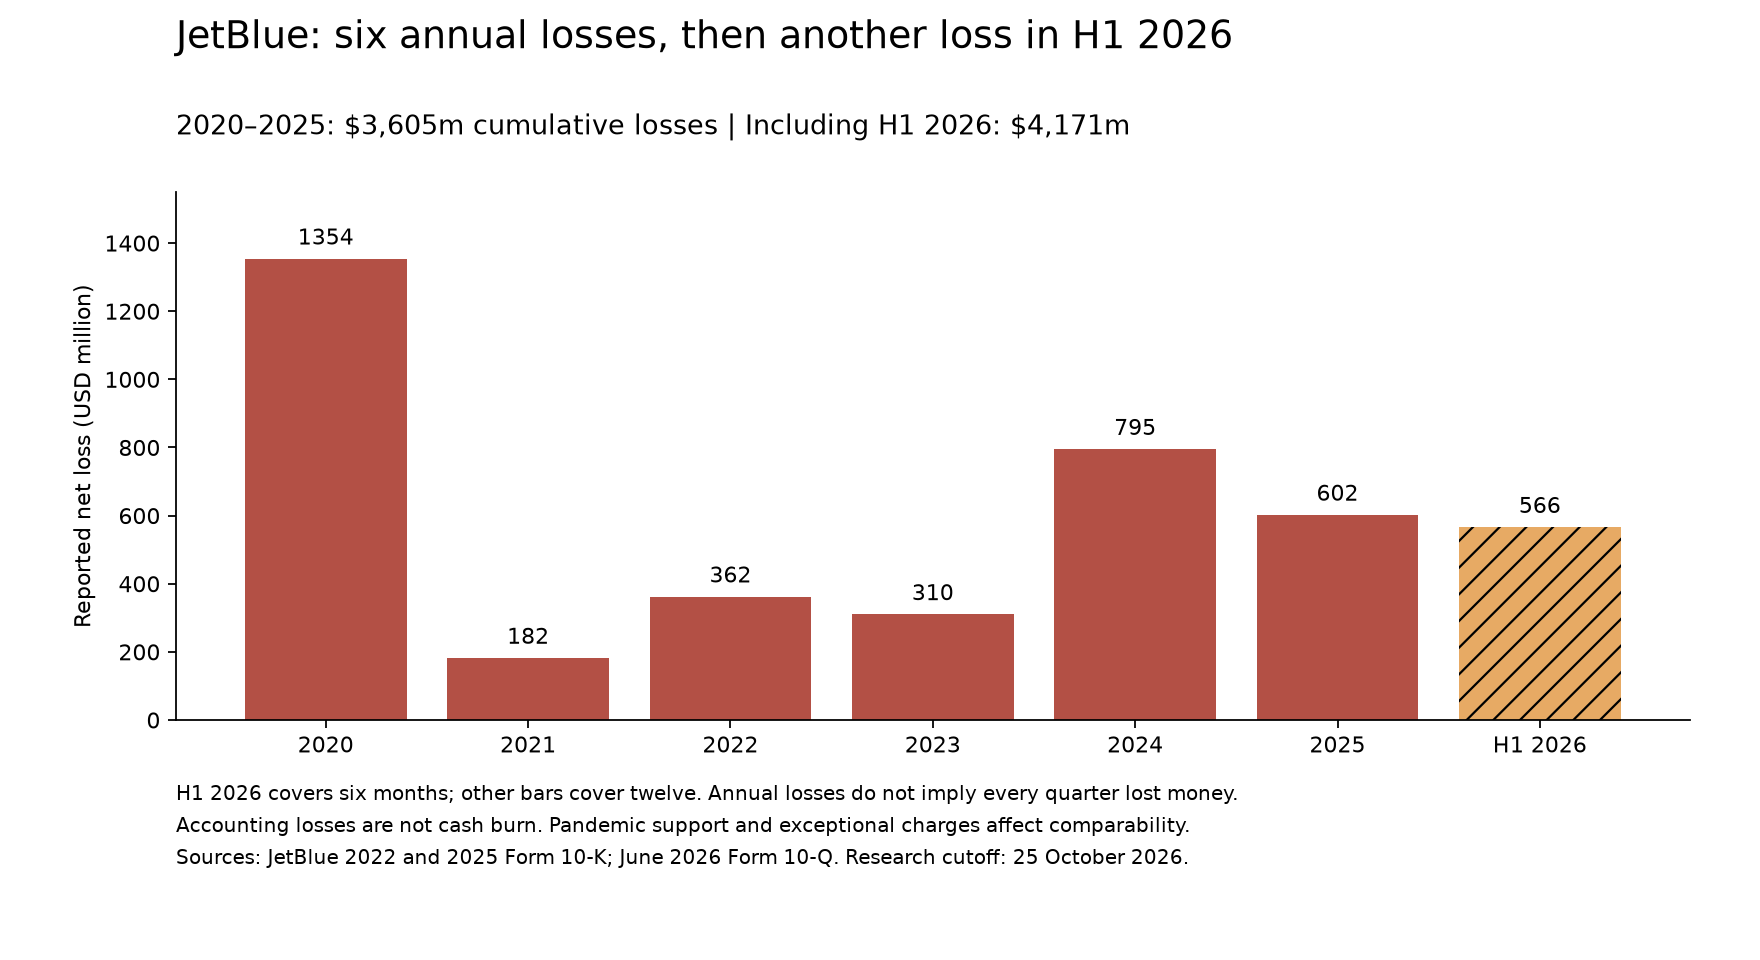

In [2]:
display(losses)
display(Image(filename=str(out/'jetblue_loss_history.png')))

## How much room remains after shocks?
The horizon runs from June 2026 to June 2027. Starting cash and investments: $2,168m. The $1bn floor is an author planning assumption, **not a covenant or management target**. Baseline consumption is the unknown cash outflow after ordinary debt service, leases, investment and working capital, before new financing and the incremental shocks. Do not deduct the debt schedule again.

Scenarios assume full cash transmission within the horizon, no demand-related cost savings, linear fuel sensitivity and no monthly timing effects. Fuel pricing recapture and demand loss are separate assumptions.

,scenario,opening_cash_and_investments,analyst_cash_floor,incremental_fuel,incremental_demand,incremental_interest,hypothetical_holdback,total_incremental_shocks,hypothetical_net_funding,maximum_baseline_cash_consumption
0,No incremental shock,2168,1000,0.0,0.00,0.0,0,0.00,0,1168.00
1,"Fuel shock, partial recovery",2168,1000,154.5,0.00,22.0,0,176.50,0,991.50
2,Combined downside,2168,1000,463.5,285.09,44.0,250,1042.59,0,125.41


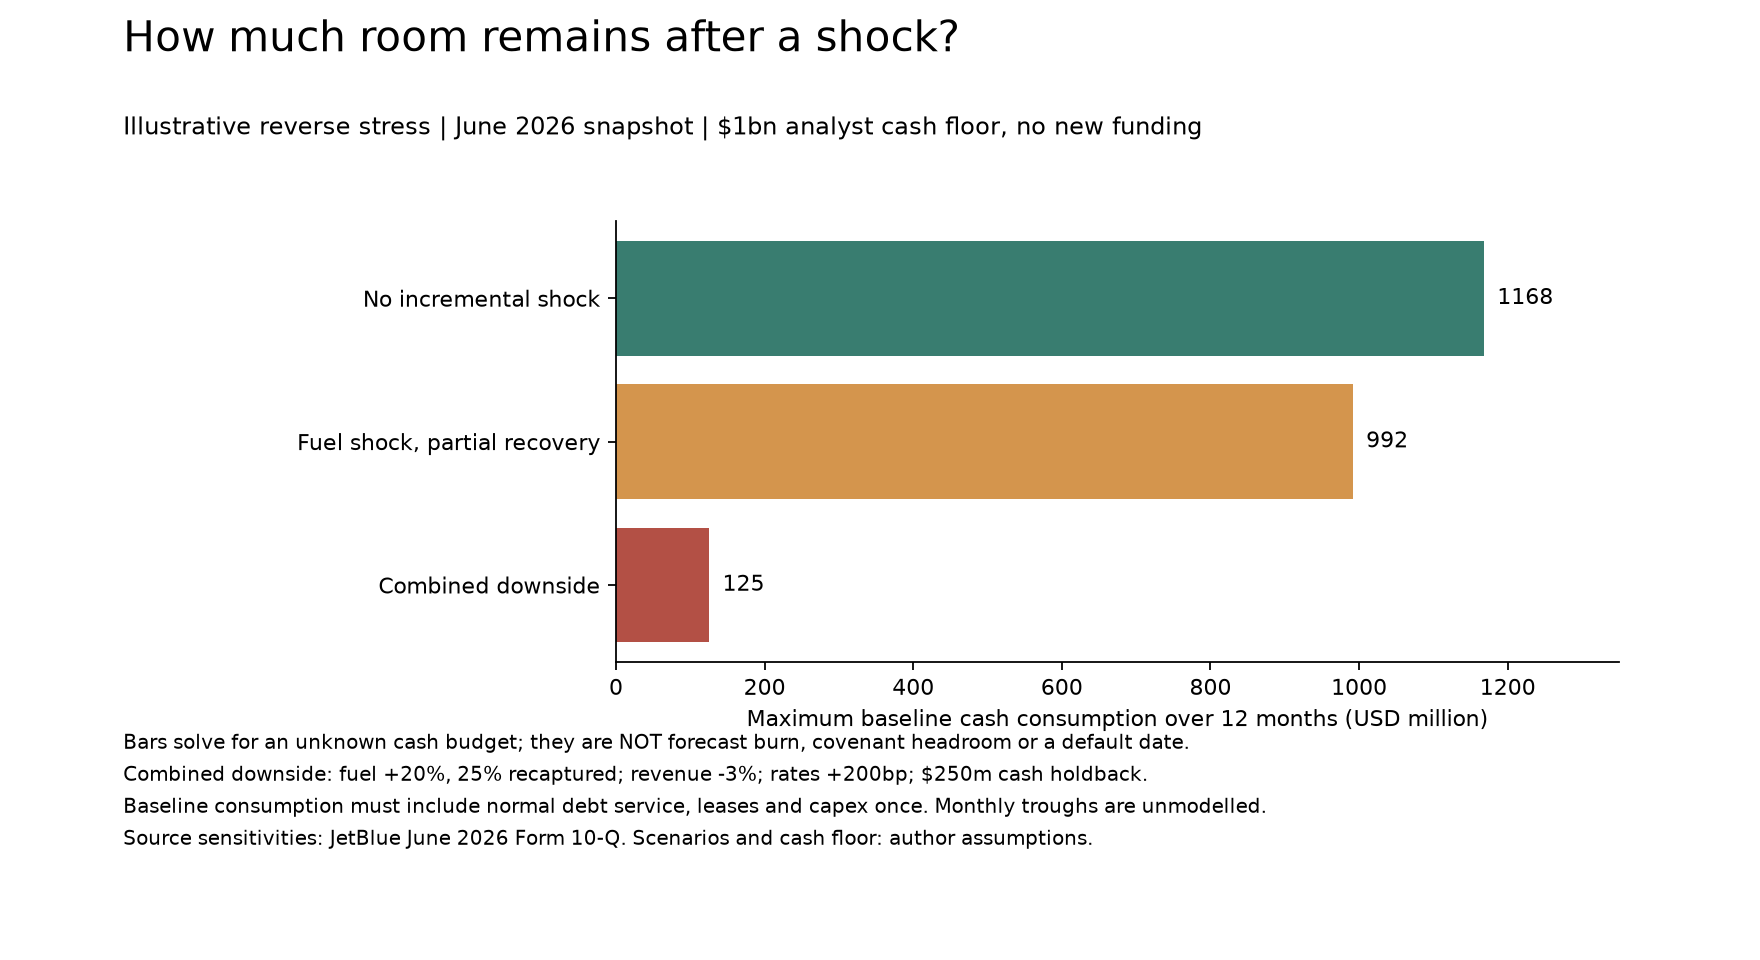

In [3]:
display(stress.round(2))
display(Image(filename=str(out/'reverse_stress.png')))

## Change the assumptions
This cell is intentionally editable. A net funding amount must be genuinely additional to opening cash and net of its costs; it is not automatically available capacity. The output solves an endpoint reserve budget, not covenant headroom or time-to-default.

In [4]:
scenario=dict(d['scenarios'][2])
planning_floor=1000
additional_net_funding=0
display(reverse_stress(d['inputs'],scenario,planning_floor,additional_net_funding))

{'scenario': 'Combined downside',
 'opening_cash_and_investments': 2168,
 'analyst_cash_floor': 1000,
 'incremental_fuel': 463.5,
 'incremental_demand': 285.09,
 'incremental_interest': 44.0,
 'hypothetical_holdback': 250,
 'total_incremental_shocks': 1042.59,
 'hypothetical_net_funding': 0,
 'maximum_baseline_cash_consumption': 125.41000000000008}

## What contractual limits matter?
The original TrueBlue indenture has a $750m agreement-defined liquidity test and a loyalty-financing coverage test stepping to 1.75x after June 2026. Eligibility rules, amendments, certificates and other facilities must be checked before calculating current headroom. Consolidated EBITDAR is not this coverage numerator. See the [trigger register](../docs/credit-story.md#a-concrete-jetblue-trigger-register).

Healthy means cash generation, manageable fixed charges and a stress-tested buffer. JetBlue and Alaska show pressure in our detailed cases; LATAM and easyJet have more encouraging features but unresolved financing evidence. The other airlines require dated current evidence before a complete comparison.

In [5]:
display(d['contract_terms'])
display(d['sources'])

{'source_url': 'https://www.sec.gov/Archives/edgar/data/1158463/000115846324000023/exhibit41-jetbluextrueblue.htm',
 'agreement_date': '2024-08-27',
 'minimum_liquidity': 750,
 'minimum_liquidity_test': 'quarter-end; agreement-defined liquidity includes eligible available revolvers, not just reported cash',
 'senior_dscr_after_june_2026': 1.75,
 'senior_ltv_early_amortization_above_pct': 62.5,
 'status': 'Original executed terms; subsequent amendments, certificates, current test values and other facilities not fully reviewed. No current covenant headroom or breach conclusion.'}

{'2022': 'https://www.sec.gov/Archives/edgar/data/1158463/000115846323000002/jblu-20221231.htm',
 '2025': 'https://www.sec.gov/Archives/edgar/data/1158463/000115846326000007/jblu-20251231.htm',
 '2026h1': 'https://www.sec.gov/Archives/edgar/data/1158463/000115846326000075/jblu-20260630.htm',
 'release': 'https://ir.jetblue.com/news/news-details/2026/JetBlue-Announces-Second-Quarter-2026-Results/default.aspx',
 'indenture': 'https://www.sec.gov/Archives/edgar/data/1158463/000115846324000023/exhibit41-jetbluextrueblue.htm',
 'fitch': 'https://investor-relations.lufthansagroup.com/fileadmin/downloads/en/more/Fitch_Deutsche_Lufthansa_AG_-_15_Sep_2026.pdf',
 'sp': 'https://investor-relations.lufthansagroup.com/fileadmin/downloads/en/more/RatingsDirect_DeutscheLufthansaAG_3616411_Aug-24-2026.pdf',
 'moodys': 'https://ratings.moodys.com/api/rmc-documents/426534',
 'ifrs': 'https://www.ifrs.org/-/media/project/leases/ifrs/published-documents/ifrs16-effects-analysis.pdf'}